In [68]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
import tensorflow
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
import os
import joblib

In [69]:
data = pd.read_csv("/content/drive/MyDrive/month_3_ann_student_performance_dataset_15000.csv")

In [70]:
data.head()

,student_id,age,attendance_pct,study_hours_per_week,previous_score,assignment_completion_pct,internal_assessment_score,participation_score,sleep_hours_per_day,extracurricular_hours_per_week,failed_subjects,performance_category
0,STU21500,24,73.8,7.9,58.3,100.0,55.6,4.7,4.9,5.0,0,Low
1,STU16476,19,58.1,3.9,61.5,100.0,55.5,8.8,5.3,0.0,1,Low
2,STU23168,18,77.5,24.5,86.2,66.9,69.3,8.3,6.6,7.1,0,High
3,STU10863,17,76.1,17.1,78.8,75.7,62.5,8.4,8.0,7.0,1,High
4,STU15971,22,86.3,4.6,76.2,79.6,72.6,5.5,6.4,2.0,0,Low


In [71]:
data.tail()

,student_id,age,attendance_pct,study_hours_per_week,previous_score,assignment_completion_pct,internal_assessment_score,participation_score,sleep_hours_per_day,extracurricular_hours_per_week,failed_subjects,performance_category
14995,STU15192,24,72.2,15.9,58.8,83.9,48.1,7.2,7.1,0.0,1,Low
14996,STU23419,20,63.6,4.5,75.2,80.2,60.7,2.8,7.8,3.6,0,Low
14997,STU15391,18,97.5,12.8,82.7,89.3,52.0,5.3,6.1,0.0,0,High
14998,STU10861,24,63.1,19.7,72.7,100.0,43.8,8.1,4.1,1.9,0,High
14999,STU17271,19,67.6,11.2,85.6,100.0,78.7,5.8,4.9,3.6,0,Medium


In [72]:
data.describe()

,age,attendance_pct,study_hours_per_week,previous_score,assignment_completion_pct,internal_assessment_score,participation_score,sleep_hours_per_day,extracurricular_hours_per_week,failed_subjects
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,20.472867,77.937073,15.171793,66.654120,75.347993,64.825980,6.151027,6.793887,5.119900,0.798133
std,2.281698,11.672369,6.842051,14.744212,15.885809,15.849283,1.950498,1.095108,3.289273,0.896941
min,17.000000,45.000000,2.000000,25.000000,20.000000,20.000000,1.000000,4.000000,0.000000,0.000000
25%,18.000000,70.000000,10.300000,56.800000,64.400000,54.100000,4.800000,6.100000,2.600000,0.000000
50%,20.000000,77.900000,15.100000,66.600000,75.900000,64.700000,6.200000,6.800000,5.000000,1.000000
75%,22.000000,86.100000,19.800000,76.600000,87.500000,75.800000,7.500000,7.500000,7.400000,1.000000
max,24.000000,100.000000,40.000000,100.000000,100.000000,100.000000,10.000000,10.000000,18.000000,5.000000


In [73]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   student_id                      15000 non-null  object 
 1   age                             15000 non-null  int64  
 2   attendance_pct                  15000 non-null  float64
 3   study_hours_per_week            15000 non-null  float64
 4   previous_score                  15000 non-null  float64
 5   assignment_completion_pct       15000 non-null  float64
 6   internal_assessment_score       15000 non-null  float64
 7   participation_score             15000 non-null  float64
 8   sleep_hours_per_day             15000 non-null  float64
 9   extracurricular_hours_per_week  15000 non-null  float64
 10  failed_subjects                 15000 non-null  int64  
 11  performance_category            15000 non-null  object 
dtypes: float64(8), int64(2), object(

In [74]:
data.shape

(15000, 12)

In [75]:
data.isnull().sum()

,0
student_id,0
age,0
attendance_pct,0
study_hours_per_week,0
previous_score,0
assignment_completion_pct,0
internal_assessment_score,0
participation_score,0
sleep_hours_per_day,0
extracurricular_hours_per_week,0


In [76]:
data.duplicated().sum()

np.int64(0)

In [77]:
data.columns

Index(['student_id', 'age', 'attendance_pct', 'study_hours_per_week',
       'previous_score', 'assignment_completion_pct',
       'internal_assessment_score', 'participation_score',
       'sleep_hours_per_day', 'extracurricular_hours_per_week',
       'failed_subjects', 'performance_category'],
      dtype='object')

In [78]:
data['performance_category'].unique()

array(['Low', 'High', 'Medium'], dtype=object)

In [79]:
data['performance_category'].value_counts()

,count
performance_category,
Medium,5100
Low,4950
High,4950


In [80]:
X = data.drop(["student_id", "performance_category"], axis=1)
y = data["performance_category"]

In [81]:
le = LabelEncoder()
y = le.fit_transform(y)

In [82]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

In [83]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [84]:
model = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Support Vector Machine": SVC()
}

Logistic Regression

              precision    recall  f1-score   support

           0       0.76      0.78      0.77       990
           1       0.77      0.71      0.74       990
           2       0.56      0.59      0.57      1020

    accuracy                           0.69      3000
   macro avg       0.70      0.69      0.69      3000
weighted avg       0.70      0.69      0.69      3000

Random Forest

              precision    recall  f1-score   support

           0       0.73      0.74      0.74       990
           1       0.74      0.69      0.72       990
           2       0.52      0.55      0.54      1020

    accuracy                           0.66      3000
   macro avg       0.67      0.66      0.66      3000
weighted avg       0.66      0.66      0.66      3000

Support Vector Machine

              precision    recall  f1-score   support

           0       0.77      0.74      0.76       990
           1       0.77      0.69      0.72       990
           2   

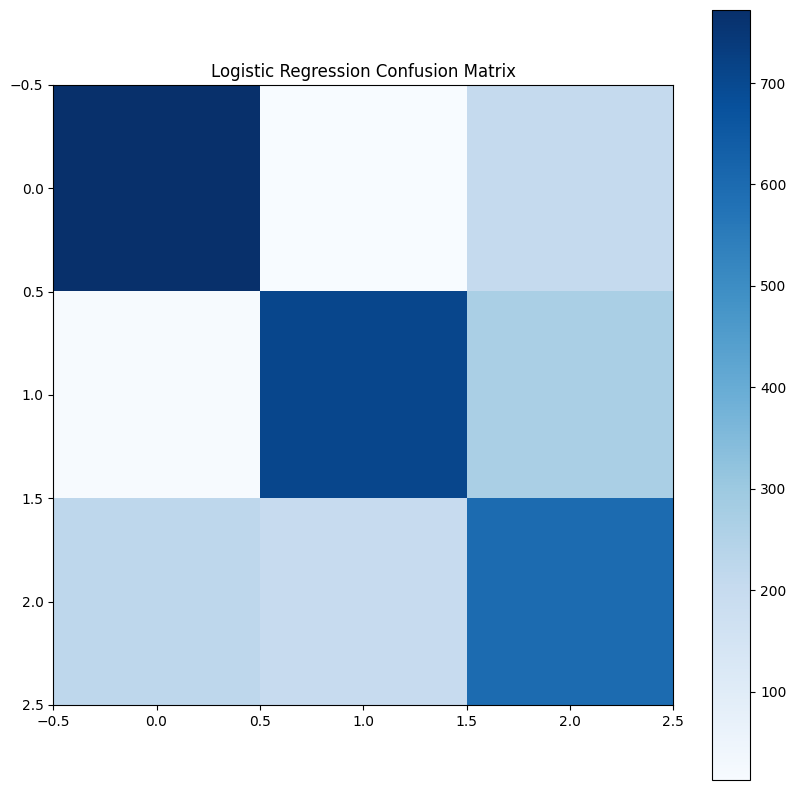

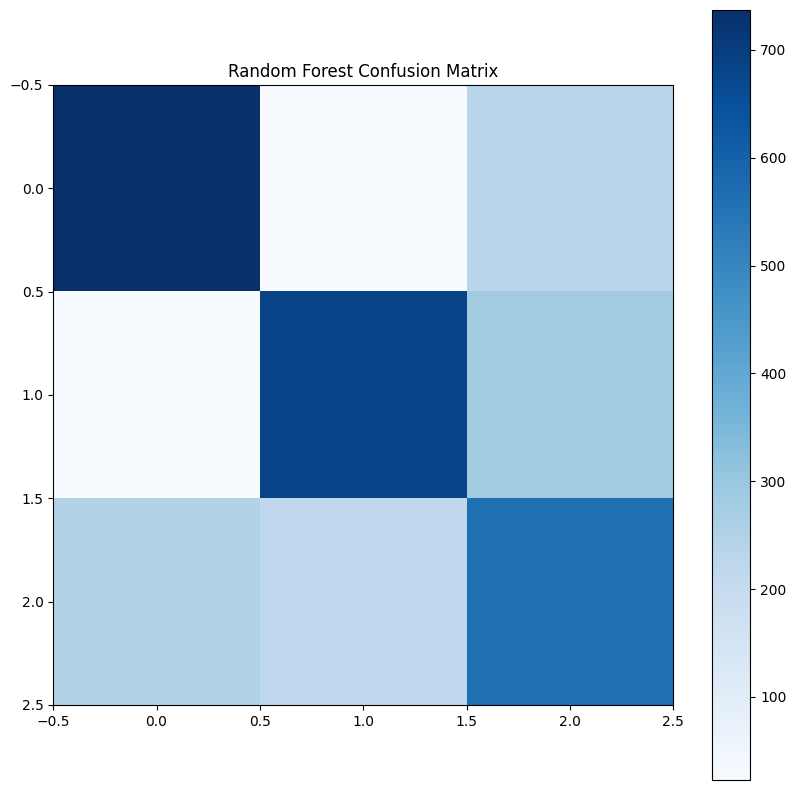

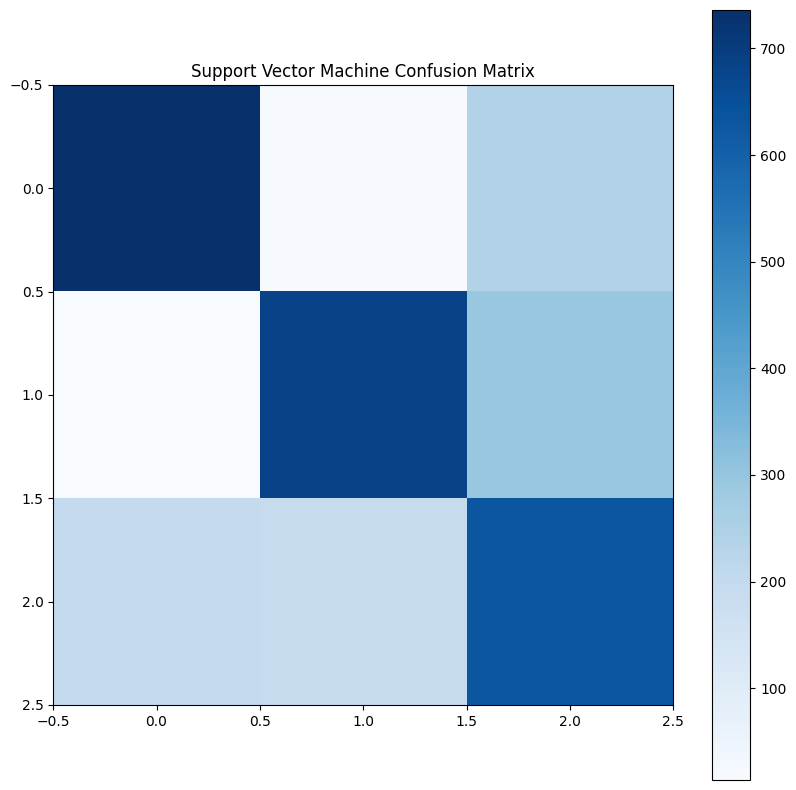

In [85]:
results = []
for model_name, clf in model.items():
  clf.fit(X_train_scaled, y_train)
  y_pred = clf.predict(X_test_scaled)
  results.append({
      "Model": model_name,
      "Accuracy": accuracy_score(y_test, y_pred),
      "Precision": precision_score(y_test, y_pred, average="weighted"),
      "Recall": recall_score(y_test, y_pred, average="weighted"),
      "F1 Score": f1_score(y_test, y_pred, average="weighted")
  })
  print(f"{model_name}\n")
  print(classification_report(y_test, y_pred))
  plt.figure(figsize=(10, 10))
  cm = confusion_matrix(y_test, y_pred)
  plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
  plt.title(f"{model_name} Confusion Matrix")
  plt.colorbar()

In [86]:
ann_model = Sequential([
    Dense(64, activation="relu", input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(3, activation="softmax")
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [87]:
ann_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

In [88]:
early_stopping = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

In [89]:
history = ann_model.fit(X_train_scaled, y_train, epochs=15, batch_size=32, validation_split=0.2, callbacks=[early_stopping])

Epoch 1/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6064 - loss: 0.8086 - val_accuracy: 0.6750 - val_loss: 0.6835
Epoch 2/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6706 - loss: 0.7030 - val_accuracy: 0.6821 - val_loss: 0.6797
Epoch 3/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6771 - loss: 0.6888 - val_accuracy: 0.6787 - val_loss: 0.6775
Epoch 4/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6849 - loss: 0.6782 - val_accuracy: 0.6779 - val_loss: 0.6767
Epoch 5/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6890 - loss: 0.6713 - val_accuracy: 0.6767 - val_loss: 0.6790
Epoch 6/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6884 - loss: 0.6651 - val_accuracy: 0.6787 - val_loss: 0.6791
Epoch 7/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6969 - loss: 0.6652 - val_accuracy: 0.6850 - val_loss: 0.6767
Epoch 8/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6928 - loss: 0.6638 - val_accuracy: 0.

In [90]:
y_prob = ann_model.predict(X_test_scaled)
y_pred = y_prob.argmax(axis=1)

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


ANN

              precision    recall  f1-score   support

           0       0.73      0.80      0.77       990
           1       0.77      0.71      0.74       990
           2       0.56      0.55      0.55      1020

    accuracy                           0.69      3000
   macro avg       0.69      0.69      0.69      3000
weighted avg       0.69      0.69      0.68      3000



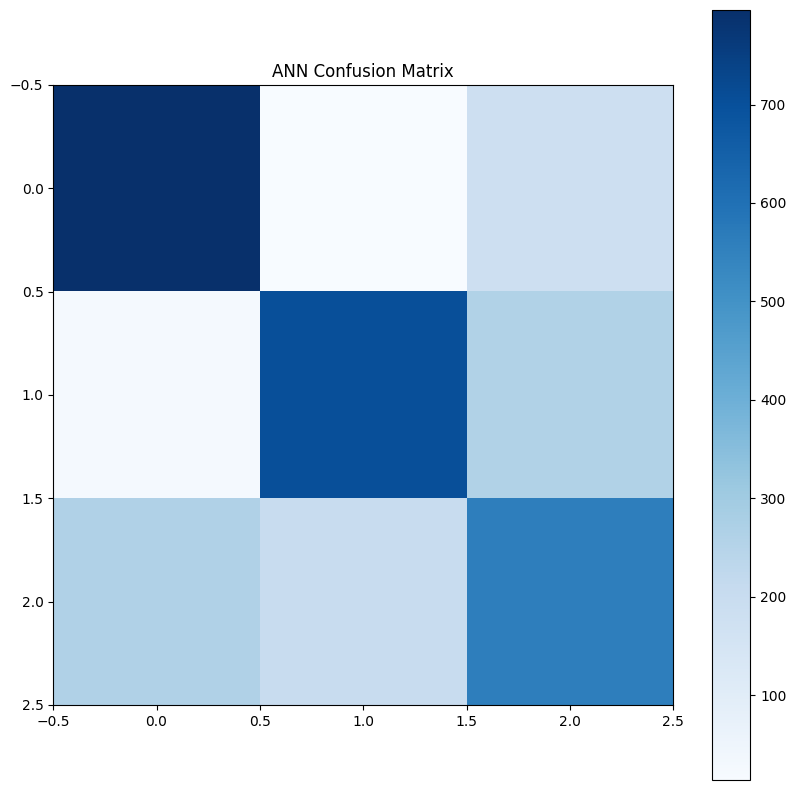

In [91]:
results.append({
    "Model": "ANN",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, average="weighted"),
    "Recall": recall_score(y_test, y_pred, average="weighted"),
    "F1 Score": f1_score(y_test, y_pred, average="weighted")
})
print("ANN\n")
print(classification_report(y_test, y_pred))
plt.figure(figsize=(10, 10))
cm = confusion_matrix(y_test, y_pred)
plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title("ANN Confusion Matrix")
plt.colorbar()

                    Model  Accuracy  Precision    Recall  F1 Score
0     Logistic Regression  0.692000   0.695762  0.692000  0.693347
1           Random Forest  0.660333   0.664272  0.660333  0.661851
2  Support Vector Machine  0.681667   0.692411  0.681667  0.685391
3                     ANN  0.685667   0.685223  0.685667  0.684546


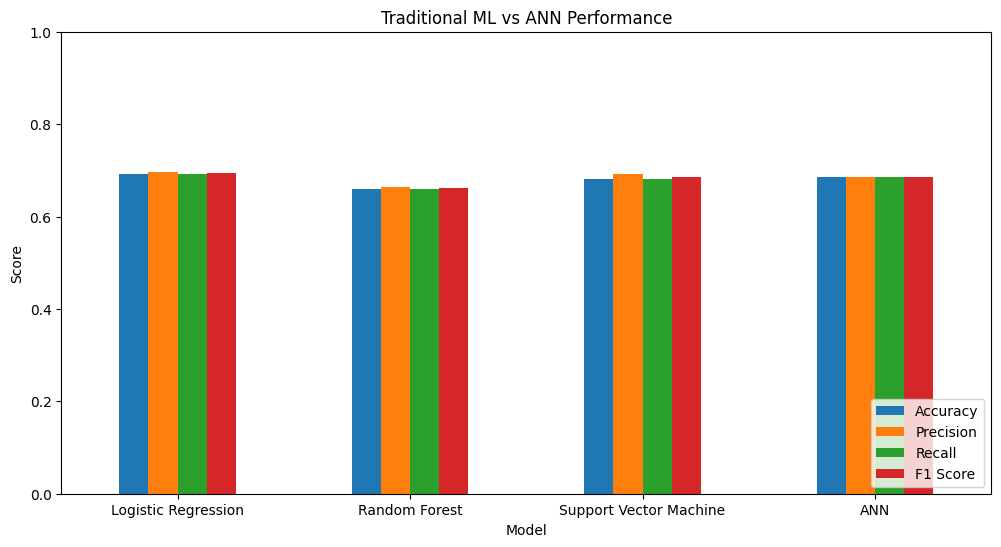

In [92]:
results_df = pd.DataFrame(results)
print(results_df)
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6)
)
plt.title("Traditional ML vs ANN Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

In [95]:
os.makedirs("models", exist_ok=True)
ann_model.save("models/student_performance_ann.keras")
for name, clf in model.items():
    joblib.dump(clf, f"models/{name.replace(' ', '_')}.pkl")
joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(le, "models/label_encoder.pkl")
print("All models and preprocessing objects saved successfully!")

All models and preprocessing objects saved successfully!
